# ЛР №7. Построение автокодировщика

**Выполнил:** Котов Дэвид Арсенович  
**Группа:**  
**Проверил:**

**Вариант 27:** 27 = (5 − 1) · 6 + 3 — набор 5 «два диска» × фактор 3 «свёрточная → полносвязная архитектура».

A — ConvAE, B — DenseAE со скрытым слоем 256. В обоих режимах латент d=8, 20 эпох, Adam, lr=0,002, batch=128, MSE, чистый вход. Данные порождаются с seed 7, seed обучения — 101–105.

Нужно измерить PSNR на тесте, разрыв train−test, параметры и время, сравнить с «средней картинкой», проверить сохранение обоих дисков и выполнить диагностику латента. Внешние данные и предобученные веса не нужны.


## 1. Цель и критерии

Изолируется поле arch; число параметров при этом тоже меняется, поэтому это не сравнение архитектур одинаковой ёмкости. Качество оценивается по отложенным 1024 сценам, с сопоставлением тривиальному эталону. Основная серия — пять пар обучений.

Учебные файлы используются без изменения текста. Отдельная лицензия на них в комплекте не указана; MIT собственного кода на них не распространяется. Обученные веса не сохраняются в репозиторий: записываются конфигурации, отпечатки и результаты.


## 2. Подготовка среды

Отдельный блокнот Google Colab, GPU T4. Предустановленный torch не заменяется; при отсутствии GPU расчёт останавливается. Версии, устройство и параметры воспроизводимости записываются фактически.


In [1]:
import os, sys, platform, subprocess, importlib, time, json
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version as pkg_version, PackageNotFoundError

T_START = time.perf_counter()
WORK = Path.cwd()
if WORK.name != "LR07":
    WORK = WORK / "LR07"
WORK.mkdir(exist_ok=True)
os.chdir(WORK)
ART = WORK / "artifacts"
ART.mkdir(exist_ok=True)
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))

import torch
if not torch.cuda.is_available():
    raise SystemExit("Выберите GPU T4 и запустите блокнот с начала: серия обучений рассчитана на GPU.")
need = []
for pkg in ("numpy", "Pillow"):
    try:
        pkg_version(pkg)
    except PackageNotFoundError:
        need.append(pkg)
if need:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    importlib.invalidate_caches()
import numpy as np
import PIL

driver = subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"],
                        capture_output=True, text=True)
ENV = dict(python=platform.python_version(), platform=platform.platform(), gpu=torch.cuda.get_device_name(0),
           gpu_memory_gib=round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
           torch=torch.__version__, numpy=np.__version__, Pillow=PIL.__version__,
           cuda_version=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
           driver=driver.stdout.strip() if driver.returncode == 0 else None,
           torch_threads=torch.get_num_threads(), cudnn_deterministic=torch.backends.cudnn.deterministic,
           cudnn_benchmark=torch.backends.cudnn.benchmark,
           deterministic_algorithms=torch.are_deterministic_algorithms_enabled())
print("Рабочая папка: LR07")
for key, value in ENV.items():
    print(key, "=", value)


Рабочая папка: LR07
python = 3.13.16
platform = Linux-6.6.159+-x86_64-with-glibc2.39
gpu = Tesla T4
gpu_memory_gib = 14.6
torch = 2.11.0+cu130
numpy = 2.4.6
Pillow = 11.3.0
cuda_version = 13.0
cudnn = 92700
driver = 580.82.07
torch_threads = 1
cudnn_deterministic = False
cudnn_benchmark = False
deterministic_algorithms = False


## 3. Учебная библиотека

lab07_lib.py сохраняется ячейкой writefile. До импорта проверяются 8679 байт и полный SHA-256 исходного файла.


In [2]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


Проверка целостности библиотеки; данные и веса сторонних моделей не загружаются.


In [3]:
import hashlib

LIB = WORK / "lab07_lib.py"
lib_bytes = LIB.read_bytes()
EXPECTED_SHA = "d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698"
if hashlib.sha256(lib_bytes).hexdigest() != EXPECTED_SHA and hashlib.sha256(lib_bytes + b"\n").hexdigest() == EXPECTED_SHA:
    lib_bytes += b"\n"
    LIB.write_bytes(lib_bytes)
LIB_SHA = hashlib.sha256(lib_bytes).hexdigest()
print("Размер:", len(lib_bytes), "SHA-256:", LIB_SHA)
assert len(lib_bytes) == 8679 and LIB_SHA == EXPECTED_SHA
sys.modules.pop("lab07_lib", None)
import lab07_lib as L
assert L.DEVICE == "cuda"
print("Устройство библиотеки:", L.DEVICE)


Размер: 8679 SHA-256: d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698
Устройство библиотеки: cuda


## 4. Гипотеза, допуски и режимы

Исходная запись — LR07/reports/journal.md, до собственного обучения.

| Метрика | Ожидание | Допуск |
| --- | --- | --- |
| PSNR теста | B ниже A более чем на 1 дБ; обе сети выше средней картинки | ±1,0 дБ |
| Разрыв train−test | B выше более чем на 0,1 дБ | ±0,1 дБ |
| Параметры | 101 035 → 1 580 552 (+1464,361 %) | ±20 % |
| Время | B ниже более чем на 20 %; это гипотеза о реализации, а не следствие числа весов | ±20 % |

Для PSNR больше — лучше; для разрыва, параметров и времени меньше — лучше по принятому правилу. Граница входит в нейтральную область. Для параметров s=0, поэтому критерий 2s не даёт стохастической информации.

Ожидается, что ConvAE лучше сохранит оба объекта; это проверяется визуально отдельно. Полносвязная сеть имеет больше весов, но не обязательно больше вычислений из-за отсутствия пространственного повторения свёрток.


In [4]:
VARIANT = 27
c, k = (VARIANT - 1) // 6, (VARIANT - 1) % 6
KIND, FACTOR = L.KINDS[c], L.FACTORS[k]
a_cfg, b_cfg = L.settings(FACTOR)
DIFF = {key: (a_cfg[key], b_cfg[key]) for key in a_cfg if a_cfg[key] != b_cfg[key]}
print("Вариант:", VARIANT, "набор:", KIND, "фактор:", FACTOR)
print("A:", a_cfg, "B:", b_cfg, "различия:", DIFF)
assert (KIND, FACTOR) == ("two_discs", "arch_conv_to_dense")
assert list(DIFF) == ["arch"] and a_cfg["d"] == b_cfg["d"] == 8

TOL = {"psnr": ("abs", 1.0), "gap": ("abs", 0.1), "params": ("rel", 0.20), "seconds": ("rel", 0.20)}
BETTER = {"psnr": +1, "gap": -1, "params": -1, "seconds": -1}
NAMES = {"psnr": "PSNR на тесте, дБ", "gap": "разрыв train−test, дБ", "params": "параметры, тыс.", "seconds": "время обучения, с"}
PARAM_COUNTS = {}
for mode, cfg in (("A", a_cfg), ("B", b_cfg)):
    model = L.build(cfg["arch"], cfg["d"])
    PARAM_COUNTS[mode] = L.n_params(model)
    print(mode, type(model).__name__, "параметров:", PARAM_COUNTS[mode])
    print(model)
    del model
assert PARAM_COUNTS == {"A": 101035, "B": 1580552}


Вариант: 27 набор: two_discs фактор: arch_conv_to_dense
A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20} B: {'arch': 'dense', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20} различия: {'arch': ('conv', 'dense')}
A ConvAE параметров: 101035
ConvAE(
  (enc): Sequential(
    (0): Conv2d(3, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1024, out_features=8, bias=True)
  )
  (dec_fc): Sequential(
    (0): Linear(in_features=8, out_features=1024, bias=True)
    (1): ReLU()
  )
  (dec): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 

## 5. Данные

Два диска разных цветов, четыре фактора — координаты обоих центров. Цвета и радиусы фиксированы. Данные одинаковы во всех обучениях: seed 7, 4096 train и 1024 test. Диски могут соприкасаться или перекрываться уже в оригинале; такой контакт не считается ошибкой реконструкции автоматически.


обучающая выборка: (4096, 3, 32, 32)  тестовая: (1024, 3, 32, 32)  факторы: (4096, 4)
значения пикселей: 0.10…1.00


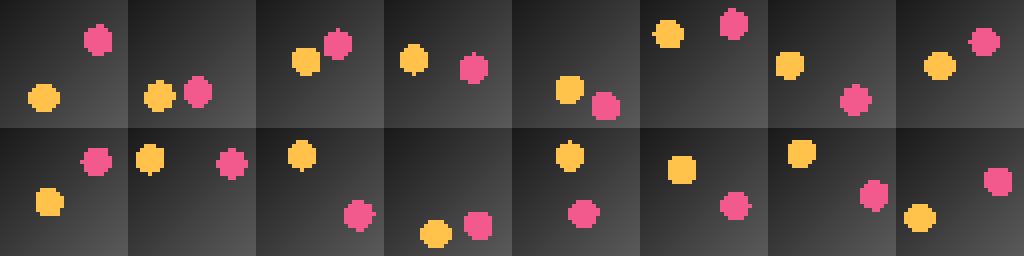

Тестовые сцены 1–8: янтарный центр x/y, розовый центр x/y, пиксели
(11.78, 18.13, 23.66, 7.78)
(5.21, 7.35, 25.41, 8.52)
(11.08, 6.34, 25.31, 21.36)
(12.5, 25.87, 23.09, 23.84)
(13.92, 6.64, 17.48, 20.78)
(10.09, 9.96, 23.34, 18.96)
(7.83, 5.76, 26.22, 16.42)
(5.55, 21.97, 25.2, 12.75)
SHA тензоров данных: {'train': '950bbb3a5ce39b2ee4dab92c14726658eec4cb4a119eba6623721685f9ba3d59', 'test': 'fdb20c9226b40a7306a70765be984c4bba1031c49e0d6ab685584fc414131781', 'train_factors': 'f8a8fa8b5bfd11850c2501d1144d6c19dad5a715d11854054ab72fb909121f82', 'test_factors': '52d93b2528087b4369abbf2c9a2045e2b3e82f3daa16f2d3eea262ed6da68c12'}


In [5]:
from PIL import Image
from IPython.display import display

Xtr, Xte, Ftr, Fte = L.dataset(KIND)
print("обучающая выборка:", tuple(Xtr.shape), " тестовая:", tuple(Xte.shape), " факторы:", tuple(Ftr.shape))
print(f"значения пикселей: {float(Xtr.min()):.2f}…{float(Xtr.max()):.2f}")


def make_sheet(rows, scale=4):
    """Лист из строк изображений (каждая строка — тензор n×3×32×32), увеличенный в scale раз."""
    grid = np.concatenate([np.concatenate(list(r.detach().permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
    img = Image.fromarray((np.clip(grid, 0, 1) * 255).round().astype("uint8"))
    return img.resize((img.width * scale, img.height * scale), Image.NEAREST)


samples = make_sheet([Xtr[:8], Xte[:8]])
samples.save(ART / "samples.png")
display(samples)
px = L.N - 1
print("Тестовые сцены 1–8: янтарный центр x/y, розовый центр x/y, пиксели")
for factors in Fte[:8].cpu().numpy():
    print(tuple(round(float(v) * px, 2) for v in (0.15 + 0.3*factors[0], 0.15 + 0.7*factors[1],
                                                     0.55 + 0.3*factors[2], 0.15 + 0.7*factors[3])))
DATA_SHA = {name: hashlib.sha256(t.detach().cpu().contiguous().numpy().tobytes()).hexdigest()
            for name, t in (("train", Xtr), ("test", Xte), ("train_factors", Ftr), ("test_factors", Fte))}
print("SHA тензоров данных:", DATA_SHA)


## 6. Эталон «средняя картинка»

Одно и то же среднее обучающих изображений выдаётся для каждого тестового входа. Значение эталона вычисляется для two_discs; число 17,171 дБ из демо другого набора не подставляется сюда. PSNR — среднее PSNR отдельных изображений, как в учебной функции.


Эталон средней картинки для two_discs: 17.310432 дБ


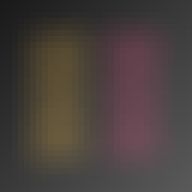

In [6]:
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
MEAN_PSNR = L.psnr_images(mean_image, Xte)
print(f"Эталон средней картинки для {KIND}: {MEAN_PSNR:.6f} дБ")
mean_sheet = make_sheet([Xtr.mean(0, keepdim=True)], scale=6)
mean_sheet.save(ART / "mean_image.png")
display(mean_sheet)


## 7. Основная серия из пяти seed

L.variant_summary выполняет прогрев A и десять измеряемых обучений. Временная обёртка сохраняет метрики каждого запуска и модели seed 101 в памяти; исходная L.run восстанавливается. Сохранение и последующий анализ не входят в время обучения.


In [7]:
RECORDS, MODELS = [], {}
_run = L.run

def run_logged(kind, cfg, seed):
    metrics, model = _run(kind, cfg, seed)
    if kind == KIND and seed in L.SEEDS:
        mode = "A" if cfg == a_cfg else "B"
        RECORDS.append(dict(mode=mode, seed=seed, **metrics))
        if seed == 101:
            MODELS[mode] = model
    return metrics, model

L.run = run_logged
t0 = time.perf_counter()
try:
    result = L.variant_summary(VARIANT)
finally:
    L.run = _run
T_SUMMARY = time.perf_counter() - t0
ROWS = {row[0]: row for row in result["rows"]}
assert len(RECORDS) == 10 and set(MODELS) == {"A", "B"}
for name, a, sd, b, delta, ratio, sig in result["rows"]:
    av = [q[name] for q in RECORDS if q["mode"] == "A"]
    bv = [q[name] for q in RECORDS if q["mode"] == "B"]
    assert np.isclose(a, np.mean(av)) and np.isclose(b, np.mean(bv)) and np.isclose(sd, np.std(av, ddof=1))
    print(f"{NAMES[name]:24s} A={a:.6f} s={sd:.6f} B={b:.6f} Δ={delta:+.6f} |Δ|/s={ratio:.3f} >2s={sig}")
print("Выигрыш над средней картинкой:", {mode: ROWS["psnr"][1 if mode == "A" else 3] - MEAN_PSNR for mode in "AB"})
print("Серия, с:", round(T_SUMMARY, 2))
print("Значения каждого обучения:")
for record in RECORDS:
    print(record)


PSNR на тесте, дБ        A=24.622640 s=0.481354 B=24.577771 Δ=-0.044869 |Δ|/s=0.093 >2s=False
разрыв train−test, дБ    A=0.074371 s=0.016278 B=0.202670 Δ=+0.128299 |Δ|/s=7.882 >2s=True
параметры, тыс.          A=101.035000 s=0.000000 B=1580.552000 Δ=+1479.517000 |Δ|/s=inf >2s=True
время обучения, с        A=1.838179 s=0.086434 B=1.182074 Δ=-0.656105 |Δ|/s=7.591 >2s=True
Выигрыш над средней картинкой: {'A': 7.3122077941894545, 'B': 7.2673385620117195}
Серия, с: 25.55
Значения каждого обучения:
{'mode': 'A', 'seed': 101, 'psnr': 24.75905990600586, 'gap': 0.06667327880859375, 'params': 101.035, 'seconds': 1.7980174109999894}
{'mode': 'B', 'seed': 101, 'psnr': 24.655723571777344, 'gap': 0.20946884155273438, 'params': 1580.552, 'seconds': 1.1559194270000148}
{'mode': 'A', 'seed': 102, 'psnr': 24.481487274169922, 'gap': 0.06444168090820312, 'params': 101.035, 'seconds': 1.7727983129999814}
{'mode': 'B', 'seed': 102, 'psnr': 24.685768127441406, 'gap': 0.20435333251953125, 'params': 1580.552, 

## 8. Допуск, 2s и чувствительность

Критерии выводятся раздельно. Для числа параметров нулевой разброс не трактуется как доказательство статистической значимости. Описательный диапазон Δ±2SE рассчитывается по парным разностям; при n=5 это не формальный 95%-й доверительный интервал.


In [8]:
def classify(metric, a, d, tol=None):
    kind, t = TOL[metric]
    t = t if tol is None else tol
    x = d if kind == "abs" else d / a
    if abs(x) <= t:
        return "нейтрально"
    return "улучшение" if (x > 0) == (BETTER[metric] > 0) else "ухудшение"


CLASSES = {}
print(f"{'метрика':24s} {'Δ':>9s} {'Δ, %':>8s} {'допуск':>9s}  {'класс':12s} |Δ|>2s  примечание")
for name, a, s, b, d, q, sig in result["rows"]:
    kind, t = TOL[name]
    cls = classify(name, a, d)
    CLASSES[name] = cls
    if name == "params":
        note = "s = 0: признак 2s неинформативен"
    elif sig != (cls != "нейтрально"):
        note = "критерий 2s и допуск расходятся"
    else:
        note = ""
    tol_txt = f"±{t:g}" if kind == "abs" else f"±{t:.0%}"
    print(f"{NAMES[name]:24s} {d:+9.3f} {100 * d / a:+7.1f}% {tol_txt:>9s}  {cls:12s} {'да' if sig else 'нет':6s} {note}")

print("\nчувствительность к допуску:")
SENS = {}
for name, tols in (("psnr", (0.25, 0.5, 1.0, 1.5, 2.0)), ("gap", (0.01, 0.02, 0.05, 0.1, 0.2))):
    _, a, s, b, d, q, sig = ROWS[name]
    pairs = [next(r[name] for r in RECORDS if r["mode"] == "B" and r["seed"] == seed) -
             next(r[name] for r in RECORDS if r["mode"] == "A" and r["seed"] == seed) for seed in L.SEEDS]
    se = float(np.std(pairs, ddof=1) / np.sqrt(len(pairs)))
    SENS[name] = {"se": se, "interval": [d - 2 * se, d + 2 * se], "by_tol": {str(t): classify(name, a, d, t) for t in tols}}
    print(f"  {NAMES[name]}: Δ = {d:+.3f}, описательный диапазон Δ ± 2·SE парных разностей = [{d - 2 * se:+.3f}; {d + 2 * se:+.3f}]")
    print("    " + "; ".join(f"допуск ±{t:g} → {classify(name, a, d, t)}" for t in tols))
    print(f"    класс меняется при допуске ±{abs(d):.3f}; "
          f"интервал {'пересекает' if (d - 2 * se) < TOL[name][1] < (d + 2 * se) or (d - 2 * se) < -TOL[name][1] < (d + 2 * se) else 'не пересекает'} "
          f"границу принятого допуска ±{TOL[name][1]:g}")

метрика                          Δ     Δ, %    допуск  класс        |Δ|>2s  примечание
PSNR на тесте, дБ           -0.045    -0.2%        ±1  нейтрально   нет    
разрыв train−test, дБ       +0.128  +172.5%      ±0.1  ухудшение    да     
параметры, тыс.          +1479.517 +1464.4%      ±20%  ухудшение    да     s = 0: признак 2s неинформативен
время обучения, с           -0.656   -35.7%      ±20%  улучшение    да     

чувствительность к допуску:
  PSNR на тесте, дБ: Δ = -0.045, описательный диапазон Δ ± 2·SE парных разностей = [-0.396; +0.306]
    допуск ±0.25 → нейтрально; допуск ±0.5 → нейтрально; допуск ±1 → нейтрально; допуск ±1.5 → нейтрально; допуск ±2 → нейтрально
    класс меняется при допуске ±0.045; интервал не пересекает границу принятого допуска ±1
  разрыв train−test, дБ: Δ = +0.128, описательный диапазон Δ ± 2·SE парных разностей = [+0.114; +0.143]
    допуск ±0.01 → ухудшение; допуск ±0.02 → ухудшение; допуск ±0.05 → ухудшение; допуск ±0.1 → ухудшение; допуск ±0.2 → не

## 9. Диагностика латентного вектора

На ConvAE набора two_discs проверяются d=1,2,3,4,8 по seed 101–103. Это отдельная диагностика, не замена сравнения двух архитектур при d=8. Четыре фактора не гарантируют плато качества ровно при d=4; результат определяется обучением. Демонстрационные числа другого набора сюда не подставляются.


In [9]:
SWEEP_D = (1, 2, 3, 4, 8)
SWEEP_SEEDS = (101, 102, 103)
SWEEP = {}
t0 = time.perf_counter()
for latent_d in SWEEP_D:
    values = []
    for seed in SWEEP_SEEDS:
        metrics, sweep_model = L.run(KIND, dict(L.BASE, d=latent_d), seed)
        values.append(metrics["psnr"])
        del sweep_model
    SWEEP[str(latent_d)] = values
    print(f"ConvAE d={latent_d}: mean PSNR={np.mean(values):.4f}, по seed={values}, выигрыш над эталоном={np.mean(values)-MEAN_PSNR:+.4f}")
T_SWEEP = time.perf_counter() - t0


ConvAE d=1: mean PSNR=18.7205, по seed=[18.938264846801758, 18.937904357910156, 18.28547477722168], выигрыш над эталоном=+1.4101
ConvAE d=2: mean PSNR=20.4473, по seed=[20.310726165771484, 20.681415557861328, 20.349746704101562], выигрыш над эталоном=+3.1369
ConvAE d=3: mean PSNR=21.2405, по seed=[20.510313034057617, 21.038955688476562, 22.17221450805664], выигрыш над эталоном=+3.9301
ConvAE d=4: mean PSNR=22.1890, по seed=[22.85485076904297, 21.691448211669922, 22.020612716674805], выигрыш над эталоном=+4.8785
ConvAE d=8: mean PSNR=24.5760, по seed=[24.848583221435547, 24.345233917236328, 24.534317016601562], выигрыш над эталоном=+7.2656


## 10. Лист сравнения

Строки: оригинал, A=ConvAE, B=DenseAE; первые восемь тестовых сцен. Обе модели взяты из основной серии с seed 101. Их повторное обучение для построения листа не требуется.


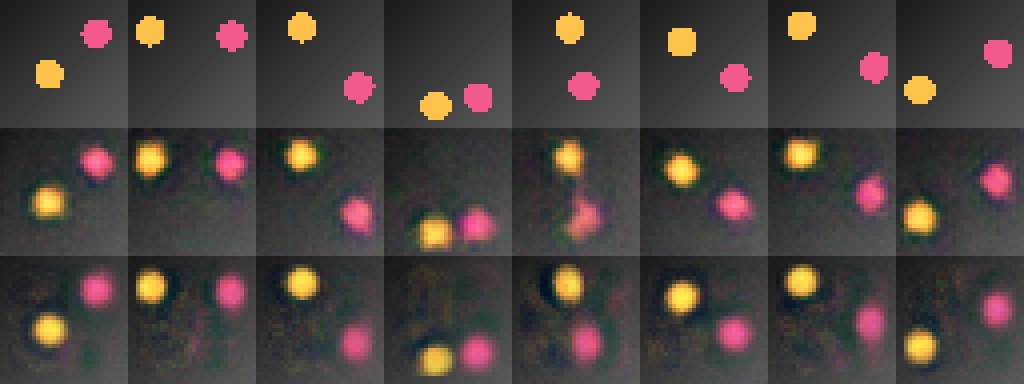

Строки: оригинал / ConvAE / DenseAE, d=8, seed 101
PSNR первых сцен: {'A': [25.334672927856445, 24.373685836791992, 25.434606552124023, 24.801301956176758, 22.27545928955078, 25.148160934448242, 24.231185913085938, 25.339937210083008], 'B': [24.900035858154297, 24.44423484802246, 24.938674926757812, 24.959327697753906, 23.430816650390625, 25.067028045654297, 24.000442504882812, 24.66402816772461]}


In [10]:
model_a, model_b = MODELS["A"], MODELS["B"]
rec_a = L.reconstruct(model_a, Xte[:8], a_cfg["eval_noise"])
rec_b = L.reconstruct(model_b, Xte[:8], b_cfg["eval_noise"])
sheet = make_sheet([Xte[:8], rec_a, rec_b])
sheet.save(ART / "comparison.png")
display(sheet)

def psnr_each(x, y):
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return (10 * torch.log10(1.0 / mse)).cpu().tolist()

COMPARISON_PSNR = {"A": psnr_each(rec_a, Xte[:8]), "B": psnr_each(rec_b, Xte[:8])}
print("Строки: оригинал / ConvAE / DenseAE, d=8, seed 101")
print("PSNR первых сцен:", COMPARISON_PSNR)


## 11. Оба диска на тестовой выборке

Янтарный и розовый объекты оцениваются раздельно по цвету; центры, площади, округлость и IoU сопоставляются с масками оригиналов. Перекрытие двух дисков возможно уже в исходной сцене. Пороговые маски помогают диагностике, но не заменяют визуальное наблюдение о сохранении двух объектов.


In [11]:
_yy, _xx = torch.meshgrid(torch.arange(L.N, dtype=torch.float32, device=L.DEVICE),
                         torch.arange(L.N, dtype=torch.float32, device=L.DEVICE), indexing="ij")

def disc_geometry(X, color):
    red, green, blue = X[:, 0], X[:, 1], X[:, 2]
    mask = (red > 0.65) & ((green-blue > 0.10) if color == "amber" else (blue-green > 0.05))
    m = mask.float()
    area = m.sum((1, 2))
    count = area.clamp_min(1)
    cx, cy = (m*_xx).sum((1, 2))/count, (m*_yy).sum((1, 2))/count
    dx, dy = _xx-cx[:, None, None], _yy-cy[:, None, None]
    vxx, vyy, vxy = (m*dx*dx).sum((1, 2))/count, (m*dy*dy).sum((1, 2))/count, (m*dx*dy).sum((1, 2))/count
    half, root = (vxx+vyy)/2, torch.sqrt(((vxx-vyy)/2)**2+vxy**2)
    rounding = torch.sqrt((half-root).clamp_min(0)/(half+root).clamp_min(1e-9))
    return dict(mask=mask, cx=cx, cy=cy, area=area, r=torch.sqrt(area/np.pi), rounding=rounding)

FULL_RECONS = {mode: L.reconstruct(model, Xte) for mode, model in MODELS.items()}
GEOMETRY = {}
for color in ("amber", "pink"):
    original = disc_geometry(Xte, color)
    GEOMETRY[color] = {"original_empty_masks": int((original["area"] == 0).sum()),
                       "original_mean_roundness": float(original["rounding"].mean())}
    for mode in "AB":
        g = disc_geometry(FULL_RECONS[mode], color)
        row = {q: dict(bias=float((g[q]-original[q]).mean()), mae=float((g[q]-original[q]).abs().mean()))
               for q in ("cx", "cy", "r", "area")}
        union = (g["mask"] | original["mask"]).sum((1, 2)).clamp_min(1)
        row.update(mean_iou=float(((g["mask"] & original["mask"]).sum((1, 2))/union).mean()),
                   empty_masks=int((g["area"] == 0).sum()), mean_roundness=float(g["rounding"].mean()))
        GEOMETRY[color][mode] = row
        print(color, mode, row)

MODEL_SHA = {mode: hashlib.sha256(b"".join(t.detach().cpu().contiguous().numpy().tobytes()
              for t in model.state_dict().values())).hexdigest() for mode, model in MODELS.items()}
RECON_SHA = {mode: hashlib.sha256(x.detach().cpu().contiguous().numpy().tobytes()).hexdigest()
            for mode, x in FULL_RECONS.items()}
print("SHA тензоров весов:", MODEL_SHA)
print("SHA тензоров реконструкций:", RECON_SHA)


amber A {'cx': {'bias': 0.012454260140657425, 'mae': 0.14961481094360352}, 'cy': {'bias': 0.04636001214385033, 'mae': 0.1384602189064026}, 'r': {'bias': -0.06335911154747009, 'mae': 0.11636372655630112}, 'area': {'bias': -1.4384765625, 'mae': 2.6767578125}, 'mean_iou': 0.8902835845947266, 'empty_masks': 0, 'mean_roundness': 0.9039726257324219}
amber B {'cx': {'bias': 0.07820764929056168, 'mae': 0.17376843094825745}, 'cy': {'bias': -0.0022550863213837147, 'mae': 0.10083292424678802}, 'r': {'bias': -0.113612100481987, 'mae': 0.12626127898693085}, 'area': {'bias': -2.6103515625, 'mae': 2.8916015625}, 'mean_iou': 0.9087589979171753, 'empty_masks': 0, 'mean_roundness': 0.9338448643684387}
pink A {'cx': {'bias': 0.06038127839565277, 'mae': 0.3238316476345062}, 'cy': {'bias': -0.055536482483148575, 'mae': 0.29321950674057007}, 'r': {'bias': -0.41680291295051575, 'mae': 0.41730058193206787}, 'area': {'bias': -8.9091796875, 'mae': 8.9208984375}, 'mean_iou': 0.7519152164459229, 'empty_masks': 0,

## Визуальная оценка

На всех восьми показанных сценах в A и B различимы янтарный и розовый диски; их взаимное положение сохранено, слияния в одно пятно не видно. В обоих режимах контуры размыты, фон приобрёл слабую неоднородность. У A розовый диск местами более тусклый и вытянутый; у B в этих сценах цветовые области обычно ровнее. Это наблюдение по листу seed 101, а не доказательство для всей выборки. В исходных данных диски могут соприкасаться или перекрываться.

На полном тесте пустых масок обоих цветов нет. IoU янтарного A/B — 0,8903/0,9088; розового — 0,7519/0,8202. Это дополнительная диагностика, не визуальная проверка всех 1024 сцен.


## 12. Повтор обучения и контрольные данные

Повторяется A с seed 101. Сравниваются PSNR, SHA тензоров весов и полного тестового выхода; метрика сама по себе не доказывает равенства весов. Затем собственная серия сопоставляется с выданной сводкой, которая не включается в собственные результаты.


In [12]:
%%writefile results_30_variants.json
[
{
"variant": 1,
"ctx": 1,
"factor": "latent_8_to_2",
"rows": [
[
"psnr",
26.1262,
0.6511,
23.1971,
-2.929100000000002,
4.498694516971282,
true
],
[
"gap",
0.0411,
0.009,
0.0992,
0.0581,
6.455555555555556,
true
],
[
"params",
101.035,
0.0,
88.741,
-12.293999999999997,
Infinity,
true
],
[
"seconds",
2.1143,
0.0877,
2.3265,
0.21219999999999972,
2.4196123147092328,
true
]
]
},
{
"variant": 2,
"ctx": 1,
"factor": "latent_8_to_32",
"rows": [
[
"psnr",
26.1448,
0.7148,
27.209,
1.0641999999999996,
1.488808058198097,
false
],
[
"gap",
0.0424,
0.0081,
0.0533,
0.0109,
1.345679012345679,
false
],
[
"params",
101.035,
0.0,
150.211,
49.176000000000016,
Infinity,
true
],
[
"seconds",
2.1389,
0.1837,
2.1743,
0.0354000000000001,
0.19270549809472018,
false
]
]
},
{
"variant": 3,
"ctx": 1,
"factor": "arch_conv_to_dense",
"rows": [
[
"psnr",
26.1129,
0.6334,
25.6936,
-0.4192999999999998,
0.6619829491632456,
false
],
[
"gap",
0.0426,
0.009,
0.1184,
0.0758,
8.422222222222224,
true
],
[
"params",
101.035,
0.0,
1580.552,
1479.5169999999998,
Infinity,
true
],
[
"seconds",
2.1261,
0.1728,
1.3483,
-0.7778,
4.501157407407407,
true
]
]
},
{
"variant": 4,
"ctx": 1,
"factor": "loss_mse_to_l1",
"rows": [
[
"psnr",
26.1,
0.6118,
16.0565,
-10.043500000000002,
16.416312520431514,
true
],
[
"gap",
0.0409,
0.0102,
0.08,
0.0391,
3.8333333333333335,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1074,
0.0751,
2.2095,
0.10209999999999964,
1.359520639147798,
false
]
]
},
{
"variant": 5,
"ctx": 1,
"factor": "input_clean_to_denoising",
"rows": [
[
"psnr",
22.4876,
3.6509,
25.5769,
3.089299999999998,
0.8461749157741921,
false
],
[
"gap",
0.0624,
0.0229,
0.0305,
-0.0319,
1.393013100436681,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.061,
0.0178,
4.5881,
2.5271,
141.97191011235955,
true
]
]
},
{
"variant": 6,
"ctx": 1,
"factor": "train_4096_to_512",
"rows": [
[
"psnr",
26.2311,
0.6863,
26.4544,
0.22329999999999828,
0.32536791490601524,
false
],
[
"gap",
0.0406,
0.0087,
0.2454,
0.2048,
23.540229885057474,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.109,
0.0848,
2.2545,
0.14550000000000018,
1.715801886792455,
false
]
]
},
{
"variant": 7,
"ctx": 2,
"factor": "latent_8_to_2",
"rows": [
[
"psnr",
26.2245,
0.657,
20.6038,
-5.620699999999999,
8.555098934550989,
true
],
[
"gap",
0.0451,
0.0105,
-0.0018,
-0.046900000000000004,
4.466666666666667,
true
],
[
"params",
101.035,
0.0,
88.741,
-12.293999999999997,
Infinity,
true
],
[
"seconds",
2.1335,
0.2102,
2.113,
-0.020500000000000185,
0.09752616555661363,
false
]
]
},
{
"variant": 8,
"ctx": 2,
"factor": "latent_8_to_32",
"rows": [
[
"psnr",
26.2222,
0.6821,
26.853,
0.6308000000000007,
0.9247910863509758,
false
],
[
"gap",
0.045,
0.0137,
0.0527,
0.0076999999999999985,
0.5620437956204378,
false
],
[
"params",
101.035,
0.0,
150.211,
49.176000000000016,
Infinity,
true
],
[
"seconds",
2.1025,
0.1042,
2.118,
0.015499999999999847,
0.1487523992322442,
false
]
]
},
{
"variant": 9,
"ctx": 2,
"factor": "arch_conv_to_dense",
"rows": [
[
"psnr",
26.1801,
0.5961,
25.8009,
-0.37920000000000087,
0.636134876698542,
false
],
[
"gap",
0.038,
0.0079,
0.1521,
0.11410000000000001,
14.443037974683543,
true
],
[
"params",
101.035,
0.0,
1580.552,
1479.5169999999998,
Infinity,
true
],
[
"seconds",
2.303,
0.1717,
1.3856,
-0.9174,
5.343040186371579,
true
]
]
},
{
"variant": 10,
"ctx": 2,
"factor": "loss_mse_to_l1",
"rows": [
[
"psnr",
26.144,
0.6699,
15.2741,
-10.869899999999998,
16.226153157187635,
true
],
[
"gap",
0.039,
0.0066,
0.0353,
-0.003700000000000002,
0.5606060606060609,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.2367,
0.2348,
2.0875,
-0.1492,
0.635434412265758,
false
]
]
},
{
"variant": 11,
"ctx": 2,
"factor": "input_clean_to_denoising",
"rows": [
[
"psnr",
24.4557,
0.3543,
25.5124,
1.0566999999999993,
2.982500705616707,
true
],
[
"gap",
0.0223,
0.0267,
0.0338,
0.011499999999999996,
0.4307116104868912,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1636,
0.1641,
4.4229,
2.2593,
13.76782449725777,
true
]
]
},
{
"variant": 12,
"ctx": 2,
"factor": "train_4096_to_512",
"rows": [
[
"psnr",
26.1826,
0.6316,
25.9444,
-0.23819999999999908,
0.37713742875237344,
false
],
[
"gap",
0.0418,
0.0069,
0.3385,
0.2967,
43.0,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1586,
0.2313,
2.0942,
-0.06440000000000001,
0.27842628620838744,
false
]
]
},
{
"variant": 13,
"ctx": 3,
"factor": "latent_8_to_2",
"rows": [
[
"psnr",
23.1424,
0.2959,
21.4339,
-1.7084999999999972,
5.773910104765114,
true
],
[
"gap",
0.0246,
0.007,
0.0763,
0.05170000000000001,
7.385714285714287,
true
],
[
"params",
101.035,
0.0,
88.741,
-12.293999999999997,
Infinity,
true
],
[
"seconds",
2.1082,
0.1278,
2.1117,
0.0034999999999998366,
0.027386541471047236,
false
]
]
},
{
"variant": 14,
"ctx": 3,
"factor": "latent_8_to_32",
"rows": [
[
"psnr",
23.0898,
0.3957,
23.7242,
0.6343999999999994,
1.603234773818548,
false
],
[
"gap",
0.0222,
0.007,
0.0249,
0.0026999999999999975,
0.38571428571428534,
false
],
[
"params",
101.035,
0.0,
150.211,
49.176000000000016,
Infinity,
true
],
[
"seconds",
2.1282,
0.1026,
2.1583,
0.030100000000000016,
0.29337231968810934,
false
]
]
},
{
"variant": 15,
"ctx": 3,
"factor": "arch_conv_to_dense",
"rows": [
[
"psnr",
23.1297,
0.2835,
22.8802,
-0.24950000000000117,
0.8800705467372176,
false
],
[
"gap",
0.0228,
0.0056,
0.1114,
0.0886,
15.821428571428571,
true
],
[
"params",
101.035,
0.0,
1580.552,
1479.5169999999998,
Infinity,
true
],
[
"seconds",
2.2351,
0.2648,
1.3493,
-0.8858000000000001,
3.345166163141995,
true
]
]
},
{
"variant": 16,
"ctx": 3,
"factor": "loss_mse_to_l1",
"rows": [
[
"psnr",
23.1517,
0.2896,
23.0093,
-0.14240000000000208,
0.49171270718232757,
false
],
[
"gap",
0.0225,
0.0058,
0.0252,
0.002700000000000001,
0.46551724137931055,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1676,
0.1377,
2.1795,
0.0118999999999998,
0.0864197530864183,
false
]
]
},
{
"variant": 17,
"ctx": 3,
"factor": "input_clean_to_denoising",
"rows": [
[
"psnr",
21.1922,
1.9681,
22.9363,
1.7440999999999995,
0.886184645089172,
false
],
[
"gap",
0.0459,
0.005,
0.0292,
-0.016700000000000003,
3.3400000000000007,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.2108,
0.2243,
4.1497,
1.9389000000000003,
8.644226482389659,
true
]
]
},
{
"variant": 18,
"ctx": 3,
"factor": "train_4096_to_512",
"rows": [
[
"psnr",
23.0734,
0.2698,
23.0976,
0.024200000000000443,
0.0896960711638267,
false
],
[
"gap",
0.0234,
0.0059,
0.1333,
0.1099,
18.627118644067796,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.0654,
0.0491,
2.1536,
0.08820000000000006,
1.7963340122199605,
false
]
]
},
{
"variant": 19,
"ctx": 4,
"factor": "latent_8_to_2",
"rows": [
[
"psnr",
21.0698,
1.0353,
19.2214,
-1.8484000000000016,
1.7853762194532998,
false
],
[
"gap",
0.0965,
0.0332,
0.0648,
-0.031700000000000006,
0.954819277108434,
false
],
[
"params",
101.035,
0.0,
88.741,
-12.293999999999997,
Infinity,
true
],
[
"seconds",
2.1884,
0.2087,
2.0855,
-0.10289999999999999,
0.4930522280785817,
false
]
]
},
{
"variant": 20,
"ctx": 4,
"factor": "latent_8_to_32",
"rows": [
[
"psnr",
20.8828,
1.0363,
22.1497,
1.2668999999999997,
1.2225224355881499,
false
],
[
"gap",
0.104,
0.0362,
0.076,
-0.027999999999999997,
0.7734806629834252,
false
],
[
"params",
101.035,
0.0,
150.211,
49.176000000000016,
Infinity,
true
],
[
"seconds",
2.1563,
0.1648,
2.1999,
0.04360000000000008,
0.264563106796117,
false
]
]
},
{
"variant": 21,
"ctx": 4,
"factor": "arch_conv_to_dense",
"rows": [
[
"psnr",
21.0541,
1.0486,
24.6924,
3.638300000000001,
3.4696738508487517,
true
],
[
"gap",
0.0929,
0.0416,
0.1836,
0.09070000000000002,
2.180288461538462,
true
],
[
"params",
101.035,
0.0,
1580.552,
1479.5169999999998,
Infinity,
true
],
[
"seconds",
2.188,
0.1561,
1.4032,
-0.7848000000000002,
5.027546444586805,
true
]
]
},
{
"variant": 22,
"ctx": 4,
"factor": "loss_mse_to_l1",
"rows": [
[
"psnr",
21.1084,
1.0458,
17.8061,
-3.302299999999999,
3.1576783323771265,
true
],
[
"gap",
0.1054,
0.0393,
0.0645,
-0.04089999999999999,
1.040712468193384,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1357,
0.2171,
2.0802,
-0.05549999999999988,
0.25564256103178207,
false
]
]
},
{
"variant": 23,
"ctx": 4,
"factor": "input_clean_to_denoising",
"rows": [
[
"psnr",
17.4467,
1.6939,
20.3733,
2.9266000000000005,
1.7277289096168609,
false
],
[
"gap",
0.0092,
0.048,
0.0677,
0.058499999999999996,
1.21875,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.0597,
0.0077,
4.4205,
2.3608,
306.59740259740255,
true
]
]
},
{
"variant": 24,
"ctx": 4,
"factor": "train_4096_to_512",
"rows": [
[
"psnr",
20.9953,
1.0157,
22.7447,
1.7494000000000014,
1.722358964261102,
false
],
[
"gap",
0.1009,
0.0257,
0.5181,
0.4172,
16.233463035019454,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.2765,
0.3009,
2.0906,
-0.18590000000000018,
0.6178132269857102,
false
]
]
},
{
"variant": 25,
"ctx": 5,
"factor": "latent_8_to_2",
"rows": [
[
"psnr",
24.7472,
0.3312,
20.3029,
-4.444299999999998,
13.41878019323671,
true
],
[
"gap",
0.0799,
0.0142,
-0.0047,
-0.0846,
5.957746478873239,
true
],
[
"params",
101.035,
0.0,
88.741,
-12.293999999999997,
Infinity,
true
],
[
"seconds",
2.1564,
0.1458,
2.1993,
0.04289999999999994,
0.29423868312757157,
false
]
]
},
{
"variant": 26,
"ctx": 5,
"factor": "latent_8_to_32",
"rows": [
[
"psnr",
24.7398,
0.3387,
26.2723,
1.5325000000000024,
4.524653085326254,
true
],
[
"gap",
0.0722,
0.0158,
0.0856,
0.013399999999999995,
0.8481012658227844,
false
],
[
"params",
101.035,
0.0,
150.211,
49.176000000000016,
Infinity,
true
],
[
"seconds",
2.1573,
0.1196,
2.2389,
0.0815999999999999,
0.6822742474916379,
false
]
]
},
{
"variant": 27,
"ctx": 5,
"factor": "arch_conv_to_dense",
"rows": [
[
"psnr",
24.6785,
0.4007,
24.5778,
-0.10069999999999979,
0.25131020713750885,
false
],
[
"gap",
0.0778,
0.0144,
0.2027,
0.1249,
8.67361111111111,
true
],
[
"params",
101.035,
0.0,
1580.552,
1479.5169999999998,
Infinity,
true
],
[
"seconds",
2.1441,
0.1884,
1.3936,
-0.7505,
3.983545647558386,
true
]
]
},
{
"variant": 28,
"ctx": 5,
"factor": "loss_mse_to_l1",
"rows": [
[
"psnr",
24.7734,
0.3443,
16.628,
-8.145399999999999,
23.657856520476326,
true
],
[
"gap",
0.0802,
0.0164,
-0.0038,
-0.08399999999999999,
5.121951219512194,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1185,
0.116,
2.0931,
-0.025399999999999867,
0.21896551724137817,
false
]
]
},
{
"variant": 29,
"ctx": 5,
"factor": "input_clean_to_denoising",
"rows": [
[
"psnr",
22.9559,
0.072,
24.7444,
1.788499999999999,
24.840277777777768,
true
],
[
"gap",
0.0668,
0.0206,
0.0655,
-0.0012999999999999956,
0.06310679611650465,
false
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1399,
0.1432,
4.3726,
2.2327000000000004,
15.591480446927378,
true
]
]
},
{
"variant": 30,
"ctx": 5,
"factor": "train_4096_to_512",
"rows": [
[
"psnr",
24.7387,
0.3645,
24.2839,
-0.4548000000000023,
1.2477366255144098,
false
],
[
"gap",
0.0758,
0.0141,
0.6148,
0.539,
38.22695035460993,
true
],
[
"params",
101.035,
0.0,
101.035,
0.0,
Infinity,
false
],
[
"seconds",
2.1158,
0.1024,
2.2255,
0.10969999999999969,
1.071289062499997,
false
]
]
}
]

Writing results_30_variants.json


In [13]:
repeat_metrics, repeat_model = L.run(KIND, a_cfg, 101)
first_metrics = next(r for r in RECORDS if r["mode"] == "A" and r["seed"] == 101)
RERUN_DIFF = repeat_metrics["psnr"] - first_metrics["psnr"]
repeat_weight_sha = hashlib.sha256(b"".join(t.detach().cpu().contiguous().numpy().tobytes()
                       for t in repeat_model.state_dict().values())).hexdigest()
repeat_rec_sha = hashlib.sha256(L.reconstruct(repeat_model, Xte).detach().cpu().contiguous().numpy().tobytes()).hexdigest()
REPEAT = dict(seed=101, first_psnr=first_metrics["psnr"], repeat_psnr=repeat_metrics["psnr"], delta_psnr=RERUN_DIFF,
              psnr_equal=repeat_metrics["psnr"] == first_metrics["psnr"], within_base_s=abs(RERUN_DIFF) <= ROWS["psnr"][2],
              weight_sha256=repeat_weight_sha, weights_equal=repeat_weight_sha == MODEL_SHA["A"],
              reconstruction_sha256=repeat_rec_sha, reconstructions_equal=repeat_rec_sha == RECON_SHA["A"])
print("Повтор A seed 101:", REPEAT)
del repeat_model

CONTROL = json.loads((WORK / "results_30_variants.json").read_text(encoding="utf-8"))
control_variant = next(row for row in CONTROL if row["variant"] == VARIANT)
assert control_variant["factor"] == FACTOR and control_variant["ctx"] == c+1
control_rows = {row[0]: row for row in control_variant["rows"]}
REFERENCE_COMPARISON = {}
for name, a, sd, b, delta, ratio, sig in result["rows"]:
    _, ra, rs, rb, rd, rr, rsign = control_rows[name]
    row = dict(own_A=a, own_B=b, own_delta=delta, reference_A=ra, reference_B=rb, reference_delta=rd,
               own_class=classify(name, a, delta), reference_class=classify(name, ra, rd),
               own_gt_2s=sig, reference_gt_2s=bool(rsign))
    if name != "seconds" and rs > 0:
        row.update(A_diff_over_reference_s=(a-ra)/rs, B_diff_over_reference_s=(b-rb)/rs)
    REFERENCE_COMPARISON[name] = row
    print(name, row)


Повтор A seed 101: {'seed': 101, 'first_psnr': 24.75905990600586, 'repeat_psnr': 24.811370849609375, 'delta_psnr': 0.052310943603515625, 'psnr_equal': False, 'within_base_s': True, 'weight_sha256': 'b4a1222044e1460fccc527cec6427e154321a9607081eefd8b3b14526fb4c039', 'weights_equal': False, 'reconstruction_sha256': '5388e5fcf85f8f5921093fbed9922907c9c4674f3b7d0fab97fa446580665469', 'reconstructions_equal': False}
psnr {'own_A': 24.622640228271486, 'own_B': 24.57777099609375, 'own_delta': -0.044869232177735086, 'reference_A': 24.6785, 'reference_B': 24.5778, 'reference_delta': -0.10069999999999979, 'own_class': 'нейтрально', 'reference_class': 'нейтрально', 'own_gt_2s': False, 'reference_gt_2s': False, 'A_diff_over_reference_s': -0.13940546974922352, 'B_diff_over_reference_s': -7.23830952062858e-05}
gap {'own_A': 0.07437057495117187, 'own_B': 0.20266990661621093, 'own_delta': 0.12829933166503904, 'reference_A': 0.0778, 'reference_B': 0.2027, 'reference_delta': 0.1249, 'own_class': 'ухудше

## 13. Демонстрационный скрипт преподавателя

lab07_demo.py запускается без изменения текста в отдельной папке. Он относится к набору «диск», латенту 8→2 и собственной диагностике. Его числа и изображение не подменяют результаты two_discs. Результат сверяется с выданной сводкой варианта 1 после своего обучения.


In [14]:
%%writefile lab07_demo.py
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet


Writing lab07_demo.py


In [15]:
import runpy
DEMO = WORK / "demo"
DEMO.mkdir(exist_ok=True)
os.chdir(DEMO)
try:
    demo_globals = runpy.run_path(str(WORK / "lab07_demo.py"), run_name="__main__")
finally:
    os.chdir(WORK)
reference_demo = next(row for row in CONTROL if row["variant"] == 1)
DEMO_COMPARE = []
for own, reference in zip(demo_globals["result"]["rows"], reference_demo["rows"]):
    name, a, sd, b, delta, ratio, sig = own
    _, ra, rs, rb, rd, rr, rsign = reference
    row = dict(metric=name, A=a, B=b, delta=delta, gt_2s=sig,
               reference_A=ra, reference_B=rb, reference_delta=rd, reference_gt_2s=bool(rsign))
    DEMO_COMPARE.append(row)
    print("Демо:", row)
DEMO_RESULT = dict(summary=[dict(metric=n, A=a, s=sd, B=b, delta=delta, ratio=float(q) if np.isfinite(q) else None, gt_2s=sig)
                           for n,a,sd,b,delta,q,sig in demo_globals["result"]["rows"]],
                   mean_image_psnr=L.psnr_images(demo_globals["mean_image"], demo_globals["Xte"]),
                   comparison=DEMO_COMPARE)
(ART / "demo").mkdir(exist_ok=True)
import shutil
shutil.copyfile(DEMO / "comparison.png", ART / "demo" / "comparison.png")
(DEMO / "comparison.png").unlink()
del demo_globals


A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  26.038 s= 0.621 B=  23.193 d=  -2.845 |d|/s=   4.58 2s=да
gap      A=   0.040 s= 0.014 B=   0.098 d=  +0.058 |d|/s=   4.30 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.876 s= 0.179 B=   1.988 d=  +0.113 |d|/s=   0.63 2s=нет
эталон «средняя картинка», PSNR на тесте: 17.171
d=1: PSNR = 20.63 дБ (по seed: 20.63, 20.71, 20.54)
d=2: PSNR = 23.16 дБ (по seed: 23.32, 23.44, 22.73)
d=3: PSNR = 25.30 дБ (по seed: 24.81, 24.85, 26.24)
d=4: PSNR = 26.46 дБ (по seed: 26.99, 26.33, 26.05)
d=8: PSNR = 25.83 дБ (по seed: 25.78, 26.56, 25.15)
Демо: {'metric': 'psnr', 'A': 26.037848281860352, 'B': 23.193035125732422, 'delta': -2.8448131561279304, 'gt_2s': True, 'reference_A': 26.1262, 'reference_B': 23.1971, 'reference_delta': -2.92

## Ограничения

Один синтетический набор и пять seed, разные архитектуры и ёмкости при одном бюджете эпох. Различия могут отражать скорость сходимости, а не только потенциальное качество сети. Свёрточная развёртка по d не является развёрткой DenseAE. Маски зависят от цветовых порогов и учитывают перекрытия оригиналов. PSNR усредняется по изображениям; оценка на PNG после округления не воспроизводит исходные float32-значения точно. Обучение на GPU может быть недетерминированным; новый сеанс проверяется отдельно и автоматически не считается выполненным.


## Сохранение результатов

Итоговый JSON отделяет собственную серию, контрольные материалы и демонстрационный запуск. Манифест включает конфигурации, происхождение данных, окружение, отпечатки моделей и файлов. Веса не сохраняются; изображения — квантованные иллюстрации, PSNR рассчитан по float32 до сохранения PNG.


In [16]:
def finite(x):
    return float(x) if np.isfinite(x) else None

T_TOTAL = time.perf_counter() - T_START
results = dict(
    lab="ЛР 7. Построение автокодировщика", student="Котов Дэвид Арсенович", variant=VARIANT,
    date_utc=datetime.now(timezone.utc).isoformat(), kind=KIND, factor=FACTOR, mode_a=a_cfg, mode_b=b_cfg,
    data_seed=7, seeds=list(L.SEEDS), environment=ENV, device=L.DEVICE,
    data_sha256=DATA_SHA, data_shapes={"train": list(Xtr.shape), "test": list(Xte.shape)},
    lab07_lib={"bytes": len(lib_bytes), "sha256": LIB_SHA}, params_exact=PARAM_COUNTS,
    tolerance={name: dict(type=value[0], value=value[1]) for name, value in TOL.items()},
    summary=[dict(metric=name, A=a, s=sd, B=b, delta=delta, abs_delta_over_s=finite(ratio), gt_2s=sig,
                  classification=CLASSES[name]) for name, a, sd, b, delta, ratio, sig in result["rows"]],
    per_seed=RECORDS, mean_image_psnr=MEAN_PSNR,
    gain_over_mean_image={"A": ROWS["psnr"][1]-MEAN_PSNR, "B": ROWS["psnr"][3]-MEAN_PSNR},
    sensitivity=SENS, latent_sweep=dict(architecture="conv", seeds=list(SWEEP_SEEDS), psnr=SWEEP),
    comparison_seed101=dict(per_image_psnr=COMPARISON_PSNR, test_indices=list(range(8)), source="main_series"),
    disc_geometry=GEOMETRY, reproducibility=REPEAT, reference_comparison=REFERENCE_COMPARISON,
    model_tensor_sha256=MODEL_SHA, reconstruction_tensor_sha256=RECON_SHA,
    tensor_hash_definition="SHA-256 concatenated contiguous CPU tensor bytes; weights in state_dict order; reconstructions NCHW float32",
    demonstration=DEMO_RESULT, timing_s=dict(summary=T_SUMMARY, sweep=T_SWEEP, total_notebook=T_TOTAL))
(ART / "results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

manifest = dict(variant=VARIANT, model_revision=LIB_SHA, models={"A": a_cfg, "B": b_cfg},
                model_tensor_sha256=MODEL_SHA, training_seeds=list(L.SEEDS), comparison_training_seed=101,
                data_seed=7, data_sha256=DATA_SHA, environment=ENV,
                optimizer="Adam", lr=0.002, batch=128, dtype="float32", epochs=20,
                files={p.relative_to(ART).as_posix(): dict(sha256=hashlib.sha256(p.read_bytes()).hexdigest(), bytes=p.stat().st_size)
                       for p in sorted(ART.rglob("*")) if p.is_file() and p.name not in ("manifest.json", "SHA256SUMS")})
(ART / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
lines = []
for p in sorted(ART.rglob("*")):
    if p.is_file() and p.name != "SHA256SUMS":
        h = hashlib.sha256(p.read_bytes()).hexdigest()
        relative = p.relative_to(ART).as_posix()
        lines.append(f"{h}  {relative}")
        print(h, p.stat().st_size, relative)
(ART / "SHA256SUMS").write_text("\n".join(lines)+"\n", encoding="utf-8")

import zipfile
from google.colab import files
archive = WORK.parent / "LR07_results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(ART.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(WORK).as_posix())
print(f"Время выполнения блокнота: {T_TOTAL/60:.1f} мин")
print("Архив: LR07_results.zip")
files.download(str(archive))


01b0b78c8baaa876bb07b1b6e06c52b567b63162236070b39d8ecd065667e971 53335 comparison.png
9e421ef21ed2dc79683354c0c990d94ca5629a7b44a7cae0b224905aa93a0cd3 46988 demo/comparison.png
a7e084baf1c56889d3408137055c17885acac248396f1133cc88b7d2dd0c9288 2339 manifest.json
1498c49cdd4a71c6389f0938097f42e7b93d19e838281ee5fc5c41d1e72188d2 2008 mean_image.png
10dd52b6eb561af3a5ef16ac69a1c408cc5361bbbf241082511962a046da9179 14595 results.json
20fa033df26ef5d634ccc3fe8663c2e79a7cb1b6b876972050886522e83c2a01 5516 samples.png
Время выполнения блокнота: 2.0 мин
Архив: LR07_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Итог и самопроверка

DenseAE не дала практически важного изменения тестового PSNR: 24,6226 → 24,5778 дБ, Δ=−0,0449 дБ при допуске ±1 дБ. Обе сети выше эталона 17,3104 дБ на 7,3122 и 7,2673 дБ. DenseAE быстрее на 35,693 %, но имеет в 15,644 раза больше параметров и увеличивает разрыв train−test на 0,1283 дБ, сверх допуска ±0,1 дБ. Для компактной модели предпочтительна ConvAE; выбор DenseAE ради скорости требует принять рост памяти весов и разрыва.

Гипотеза о снижении PSNR B более чем на 1 дБ не подтвердилась. Прогноз роста разрыва и сокращения времени подтвердился; аналитическое число параметров совпало. Визуальное преимущество A не установлено: на seed 101 IoU обоих цветов выше у B. Пороги после запуска не менялись.

Повтор A, seed 101: PSNR 24,759060 → 24,811371 дБ, Δ=+0,052311 дБ < s базы 0,481354 дБ. SHA тензоров весов и реконструкций различаются; побитовой воспроизводимости нет. Детерминированные алгоритмы и cudnn.deterministic выключены. Это согласуется с недетерминированностью GPU, но единственную причину опыт не устанавливает. Новый сеанс отдельно не проверялся.

Диагностика ConvAE: средний PSNR при d=1,2,3,4,8 — 18,7205; 20,4473; 21,2405; 22,1890; 24,5760 дБ. При d=4 плато нет: переход к d=8 даёт +2,3871 дБ. Это новые обучения; значение d=8 может отличаться от основной серии.

Проверены все 6 записей SHA256SUMS, 5 записей manifest.json и целостность четырёх PNG. Сводка независимо пересчитана по десяти значениям A/B; встроенные учебные скрипты совпали с исходниками, контрольный JSON — по содержимому. Все 16 кодовых ячеек выполнены последовательно, ошибок нет. Обучение и GPU-время локально повторно не измерялись. Визуальный разбор и итог добавлены после просмотра сохранённых изображений.

## Краткий паспорт

Google Colab, Tesla T4; Python 3.13.16, torch 2.11.0+cu130, CUDA 13.0, cuDNN 92700, numpy 2.4.6, Pillow 11.3.0. Данные seed 7: 4096 train, 1024 test; RGB float32 3×32×32. ConvAE/DenseAE, d=8, 20 эпох, Adam lr=0,002, batch=128, MSE. Seed обучения 101–105. Библиотека SHA-256 d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698. Полные параметры, среда и отпечатки: LR07/artifacts/results.json; паспорт: LR07/reports/passport.md.
